# MLP

**Run this notebook:** in Colab, choose **Runtime → Run all**. The first cell prepares METIS automatically using uv; a fresh runtime needs this setup again. These short tutorials use a CPU. Locally, select your [METIS Python environment](https://ojwatson.github.io/metis/basics/installing_metis.html).

The outputs below were generated when the documentation was built. [Source revision `0533e26bcabc`](https://github.com/OJWatson/metis/tree/0533e26bcabc75285429cda8181f1c8489e861ef).

In [ ]:
#@title Prepare METIS (run once per runtime)
"""Embedded in notebook downloads: prepare their disposable Colab runtime with uv."""

import importlib
import importlib.metadata
import importlib.util
import io
import json
import os
from pathlib import Path
import platform
import re
import shutil
import subprocess
import sys
import tarfile
import urllib.request


UV_VERSION = "0.7.22"
INSTALL_GUIDE = "https://ojwatson.github.io/metis/basics/installing_metis.html"


def _installed_version(package):
    try:
        return importlib.metadata.version(package)
    except importlib.metadata.PackageNotFoundError:
        return None


def _compatible_pin(package, minimum, maximum=None):
    """Preserve compatible binary libraries already supplied by Colab."""
    version = _installed_version(package)
    if version is None:
        return None
    match = re.match(r"^(\d+)\.(\d+)(?:\.(\d+))?", version)
    if match is None:
        return None
    release = tuple(int(value or 0) for value in match.groups())
    if release < minimum or (maximum is not None and release >= maximum):
        return None
    return f"{package}=={version}"


def _uv_executable(directory):
    installed = shutil.which("uv")
    if installed:
        return installed
    destination = directory / "uv"
    if not destination.exists():
        architecture = {"x86_64": "x86_64", "aarch64": "aarch64"}.get(platform.machine())
        if architecture is None:
            raise RuntimeError(f"Unsupported Colab CPU architecture: {platform.machine()}")
        archive_name = f"uv-{architecture}-unknown-linux-gnu"
        url = (
            f"https://github.com/astral-sh/uv/releases/download/{UV_VERSION}/"
            f"{archive_name}.tar.gz"
        )
        with urllib.request.urlopen(url, timeout=120) as response:
            archive_bytes = response.read()
        with tarfile.open(fileobj=io.BytesIO(archive_bytes), mode="r:gz") as archive:
            # Read one known member, without extracting arbitrary archive paths.
            binary = archive.extractfile(f"{archive_name}/uv")
            if binary is None:
                raise RuntimeError("The uv release archive contains no executable")
            destination.write_bytes(binary.read())
        destination.chmod(0o755)
    return str(destination)


def _project_text(revision):
    dependencies = [
        f"metis-surrogate[plots,pandas] @ git+https://github.com/OJWatson/metis.git@{revision}",
        "torch==2.10.0",
    ]
    for package, minimum, maximum in [
        ("numpy", (2, 0, 0), (3, 0, 0)),
        ("matplotlib", (3, 9, 0), (4, 0, 0)),
        ("pandas", (2, 2, 0), (4, 0, 0)),
        ("pyarrow", (18, 0, 0), None),
        ("polars", (1, 37, 0), (3, 0, 0)),
    ]:
        pin = _compatible_pin(package, minimum, maximum)
        if pin:
            dependencies.append(pin)
    return (
        '[project]\nname = "metis-colab-tutorial"\nversion = "0.0.0"\n'
        f'requires-python = ">={sys.version_info.major}.{sys.version_info.minor},'
        f'<{sys.version_info.major}.{sys.version_info.minor + 1}"\n'
        f"dependencies = {json.dumps(dependencies)}\n\n"
        '[tool.uv]\npackage = false\n\n'
        '[tool.uv.sources]\ntorch = { index = "pytorch-cpu" }\n\n'
        '[[tool.uv.index]]\nname = "pytorch-cpu"\n'
        'url = "https://download.pytorch.org/whl/cpu"\nexplicit = true\n'
    )


def _metis_origin():
    try:
        return importlib.metadata.distribution("metis-surrogate").read_text("direct_url.json")
    except importlib.metadata.PackageNotFoundError:
        return None


def prepare_colab(revision):
    """Install only inside Colab; local notebooks use the selected METIS environment."""
    if not re.fullmatch(r"[a-f0-9]{40}", revision):
        raise ValueError("Notebook setup needs an exact 40-character source revision")
    try:
        in_colab = (
            importlib.util.find_spec("google.colab") is not None
            and bool(os.environ.get("COLAB_RELEASE_TAG") or os.environ.get("COLAB_BACKEND_VERSION"))
        )
    except ModuleNotFoundError:
        in_colab = False
    if not in_colab:
        if _installed_version("metis-surrogate") is None:
            raise RuntimeError(f"Select a Python environment containing METIS: {INSTALL_GUIDE}")
        print(f"Using local METIS {_installed_version('metis-surrogate')}.")
        return
    if sys.version_info < (3, 11):
        raise RuntimeError("This tutorial requires a Colab runtime with Python 3.11 or newer.")

    directory = Path("/content/.metis-notebooks")
    directory.mkdir(parents=True, exist_ok=True)
    (directory / "pyproject.toml").write_text(_project_text(revision), encoding="utf-8")
    loaded = {
        package: str(getattr(sys.modules[package], "__version__", _installed_version(package)))
        for package in ("numpy", "pandas", "torch", "matplotlib", "pyarrow", "polars")
        if package in sys.modules
    }
    metis_was_loaded = "metis" in sys.modules
    previous_metis_origin = _metis_origin()
    if metis_was_loaded:
        # Retain the import's identity if the user reruns setup after a restart
        # warning without actually restarting the Python process.
        previous_metis_origin = sys.modules["metis"].__dict__.setdefault(
            "_notebook_runtime_origin", previous_metis_origin,
        )
    environment = os.environ.copy()
    # Colab is a disposable runtime. Keep its unrelated packages and its active
    # notebook interpreter, instead of adding a second environment to sys.path.
    environment["UV_PROJECT_ENVIRONMENT"] = sys.prefix
    environment.pop("VIRTUAL_ENV", None)
    print("Preparing this Colab runtime with uv (CPU tutorial environment)…")
    result = subprocess.run(
        [_uv_executable(directory), "sync", "--inexact", "--no-dev", "--no-editable",
         "--project", str(directory), "--python", sys.executable],
        env=environment, text=True, capture_output=True,
    )
    if result.returncode:
        raise RuntimeError(f"METIS setup failed:\n{result.stdout}\n{result.stderr}")
    importlib.invalidate_caches()
    changed = [package for package, before in loaded.items() if _installed_version(package) != before]
    if metis_was_loaded and _metis_origin() != previous_metis_origin:
        changed.append("metis")
    if changed:
        raise RuntimeError(
            "Setup updated already-loaded libraries (" + ", ".join(changed) + "). "
            "Choose Runtime > Restart session, then Run all. Setup will reuse its installed packages."
        )
    print(f"METIS {_installed_version('metis-surrogate')} is ready. Continue with the tutorial.")


prepare_colab("0533e26bcabc75285429cda8181f1c8489e861ef")


The MLP (MultiLayer Perceptron) or *feedforward neural network* is METIS's most basic architecture.

## When this might be a good fit

The MLP is a good starting point for datasets with only static inputs. It is very fast to train and generate predictions from. Unlike the Normalising Flow or Flow Matching architectures, the MLP is a deterministic surrogate. Compare validation performance before choosing a more complex model.


## How does an MLP work?

### Architectural walkthrough
An MLP's computation is a series of matrix multiplications composed with non-linear activations. METIS's implementation also includes *residual* connections which stabilise the training of deeper networks.

In order to get a better sense of how these components work let's trace through the network's forward computation:


```python
x = self.input_layer(inputs)
for block in self.blocks:
    x = block(x)
x = self.output_layer(x)
```

The input_layer linearly projects (i.e. a matrix multiplication) the static input vector to vectors the size of the model's hidden dimension. Next, we iteratively pass our transformed inputs through a series of residual blocks.

Each residual block applies several layers to the input and adds the result back to the original input:

![Residual block structure.](https://ojwatson.github.io/metis/models/images/residual-block.png)

Finally, the output layer linearly projects `x` to the output dimensionality.

### Training
The MLP is trained to minimise the mean squared error between standardized predictions and simulations:

$$
\mathrm{Loss} = \frac{1}{M}\sum_{m=1}^{M}(\mathrm{MLP}^{\theta}(\mathrm{static\_input}_m)-\mathrm{output}_m)^2
$$

## Configuring an MLP

Pass architecture options to `Surrogate("mlp", model_options={...})`:

| Option | Meaning | Default |
|---|---|---:|
| `hidden_dim` | Width of the hidden layers | 64 |
| `num_blocks` | Number of residual blocks | 2 |
| `num_layers_per_block` | Layers in each residual block | 2 |

Input and output dimensions are inferred from the simulation bank. The same
options can be set through [Hydra](https://ojwatson.github.io/metis/basics/hydra.html):

```bash
uv run metis train model=mlp model.model_options.hidden_dim=128
```

## Training on SIRDS

We use the same [SIRDS simulations](https://ojwatson.github.io/metis/basics/sirds-example.html) and grouped
train/validation/test split as the [training tutorial](https://ojwatson.github.io/metis/basics/training.html).
This small CPU fit uses 1,000 optimizer steps.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from metis import load_example, Surrogate, TrainingConfig

bank = load_example()
split = bank.split(seed=42)

In [2]:
model = Surrogate(
    "mlp",
    model_options={"hidden_dim": 64, "num_blocks": 2, "num_layers_per_block": 2},
).fit(
    split.train, split.validation,
    config=TrainingConfig(steps=1000, batch_size=64, eval_every=100, seed=42),
)

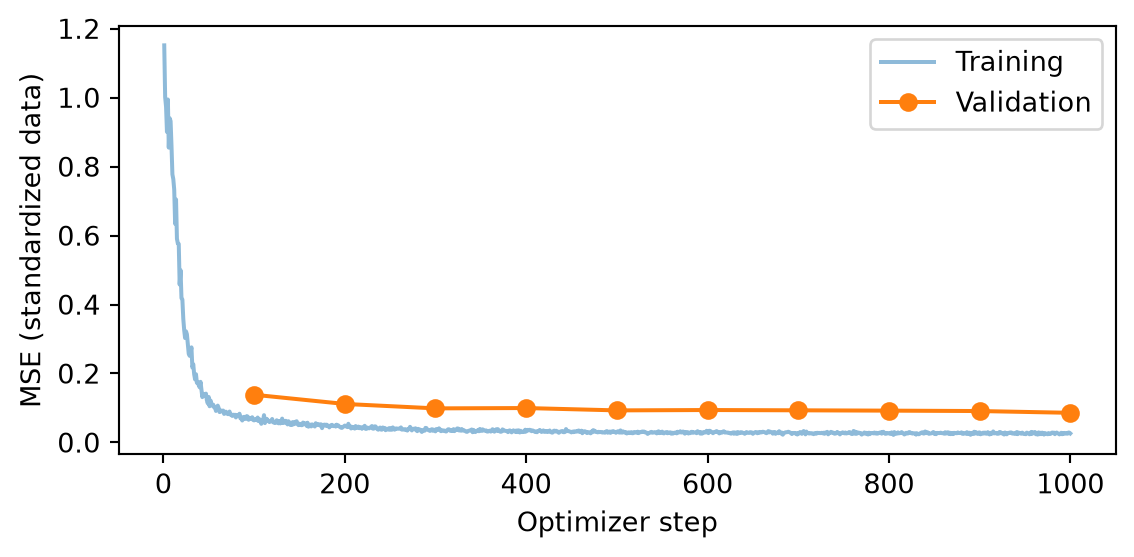

In [3]:
#| code-fold: true
#| code-summary: "Plot training and validation loss"
#| fig-cap: "MLP: training and validation loss for the bundled SIRDS bank."
validation = [row for row in model.history if "validation_loss" in row]
fig, ax = plt.subplots(figsize=(6, 3))
ax.plot([row["step"] for row in model.history],
        [row["train_loss"] for row in model.history], alpha=0.5, label="Training")
ax.plot([row["step"] for row in validation],
        [row["validation_loss"] for row in validation], "o-", label="Validation")
ax.set(xlabel="Optimizer step", ylabel="MSE (standardized data)")
ax.legend()
fig.tight_layout()
plt.show()

*MLP: training and validation loss for the bundled SIRDS bank.*

Predict an entire trajectory at the first held-out parameter setting. A
deterministic prediction aims to capture the conditional average, whereas the
simulator produces different realisations at the same inputs.

In [4]:
inputs = split.test.inputs[:1]
prediction = model.predict(inputs)[0]
print("Predicted times × outputs:", prediction.shape)

Predicted times × outputs: (40, 4)


/home/runner/work/metis/metis/src/metis/surrogate.py:672: UserWarning: Inputs outside the training ranges for ['I_0']; predictions extrapolate and are not clipped.
  array = self._inputs(inputs)


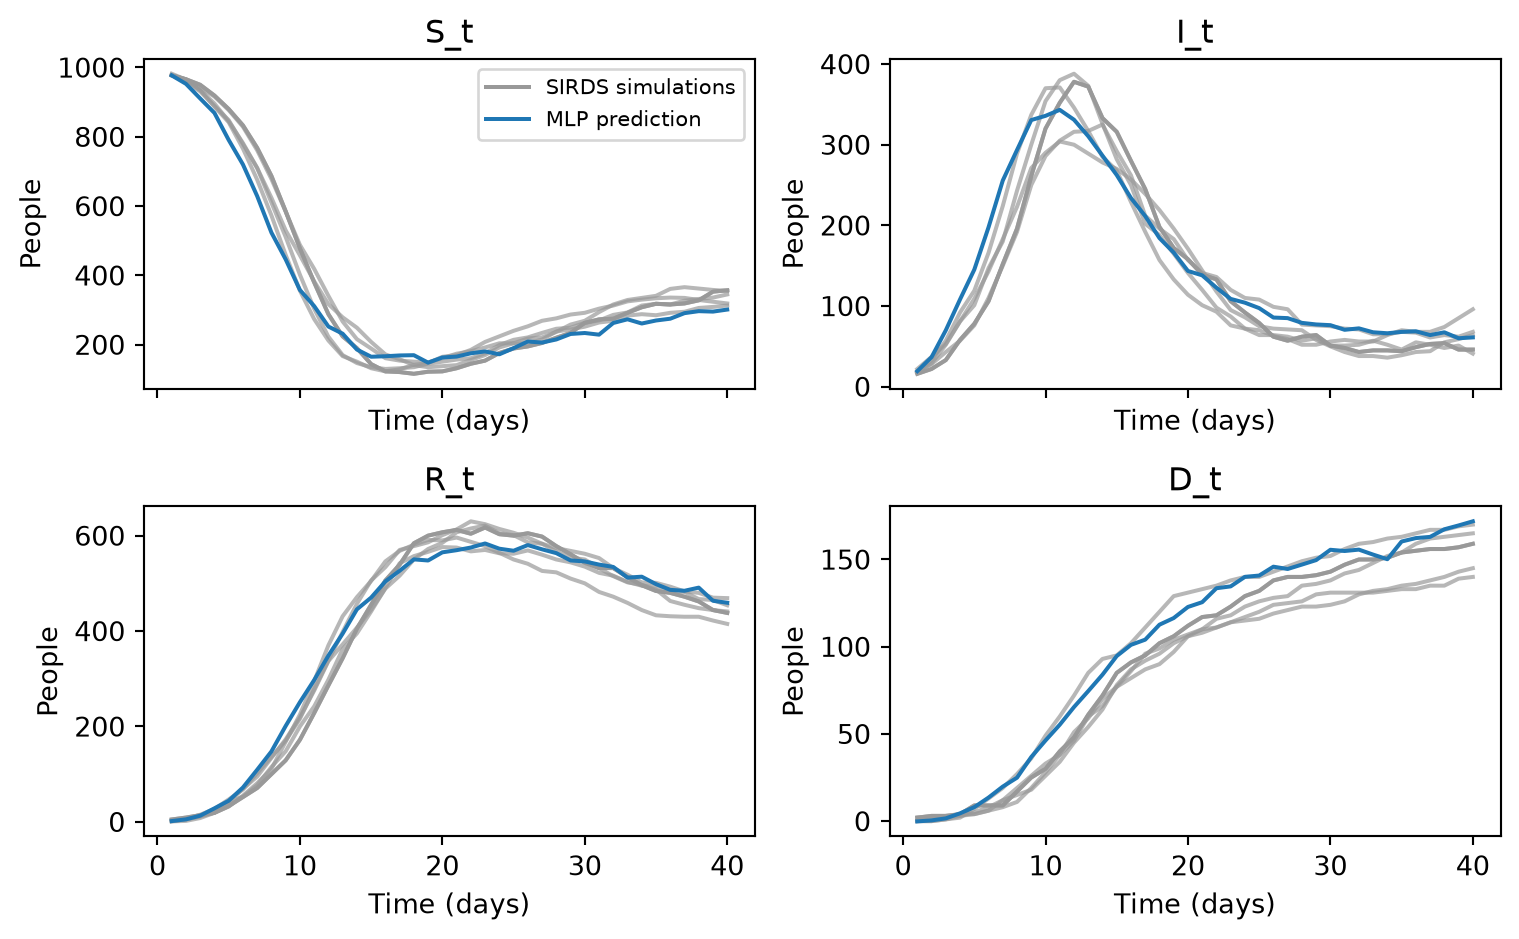

In [5]:
#| code-fold: true
#| code-summary: "Compare the prediction with SIRDS simulations"
#| fig-cap: "MLP: prediction and five SIRDS simulations at the first held-out parameter setting. The model was fitted to the training split of the bundled SIRDS bank."
same_inputs = np.all(split.test.inputs == inputs[0], axis=1)
replicates = split.test.outputs[same_inputs]
fig, axes = plt.subplots(2, 2, figsize=(8, 5), sharex=True)
for channel, ax in enumerate(axes.flat):
    ax.plot(bank.times, replicates[:, :, channel].T, color="0.6", alpha=0.7)
    ax.plot(bank.times, replicates[0, :, channel], color="0.6", label="SIRDS simulations")
    ax.plot(bank.times, prediction[:, channel], color="C0", label="MLP prediction")
    ax.set(title=bank.output_names[channel], xlabel="Time (days)", ylabel="People")
axes[0, 0].legend(fontsize=8)
fig.tight_layout()
plt.show()

*MLP: prediction and five SIRDS simulations at the first held-out parameter setting. The model was fitted to the training split of the bundled SIRDS bank.*

Compare predictions over the whole held-out bank, not just one setting; the
[training tutorial](https://ojwatson.github.io/metis/basics/training.html) shows how to evaluate the fit.